In [2]:
%matplotlib inline
import datacube, numpy as np, pandas as pd, matplotlib.pyplot as plt
import geopandas as gpd
from odc.geo.geom import Geometry
from deafrica_tools.datahandling import load_ard
from deafrica_tools.bandindices import calculate_indices
from deafrica_tools.areaofinterest import define_area

In [3]:
dc = datacube.Datacube(app="task1")

In [4]:
lat = 7.31112
lon = -1.57730
buffer = 0.04
date = '2020-08-01'

In [5]:
# Study area (same one you'll reuse in Tasks 2-4)
aoi = define_area(lat, lon, buffer)
geom = Geometry(aoi["features"][0]["geometry"], crs="epsg:4326")
gdf = gpd.GeoDataFrame(geometry=[geom], crs=geom.crs)
lon_range = (gdf.total_bounds[0], gdf.total_bounds[2])
lat_range = (gdf.total_bounds[1], gdf.total_bounds[3])



In [6]:
query = dict(x=lon_range, y=lat_range,
             time=("2019-01-01", "2023-12-31"),
             resolution=(-10, 10), output_crs="EPSG:6933")

ds = load_ard(dc=dc, products=["s2_l2a"],
              measurements=["red", "green", "blue", "nir"],
              min_gooddata=0.7, group_by="solar_day", **query)

# Both indices from the same images
ds = calculate_indices(ds, index=["NDVI", "EVI"], satellite_mission="s2")

# Keep cropland pixels only
cm = dc.load(product="crop_mask", time=("2019"), measurements="filtered",
             resampling="nearest", like=ds.geobox).filtered.squeeze()
ds = ds.where(cm == 1)

Using pixel quality parameters for Sentinel 2
Finding datasets
    s2_l2a
Counting good quality pixels for each time step


/opt/venv/lib/python3.12/site-packages/rasterio/warp.py:385: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


Filtering to 141 out of 361 time steps with at least 70.0% good quality pixels
Applying pixel quality/cloud mask
Loading 141 time steps


In [8]:
print(ds)


<xarray.Dataset> Size: 3GB
Dimensions:      (time: 141, y: 1014, x: 773)
Coordinates:
  * time         (time) datetime64[ns] 1kB 2019-01-02T10:38:57 ... 2023-12-27...
  * y            (y) float64 8kB 9.353e+05 9.353e+05 ... 9.252e+05 9.252e+05
  * x            (x) float64 6kB -1.56e+05 -1.56e+05 ... -1.483e+05 -1.483e+05
    spatial_ref  int32 4B 6933
Data variables:
    red          (time, y, x) float32 442MB nan nan nan 1.24e+03 ... nan nan nan
    green        (time, y, x) float32 442MB nan nan nan ... nan nan nan
    blue         (time, y, x) float32 442MB nan nan nan 779.0 ... nan nan nan
    nir          (time, y, x) float32 442MB nan nan nan ... nan nan nan
    NDVI         (time, y, x) float32 442MB nan nan nan 0.3913 ... nan nan nan
    EVI          (time, y, x) float32 442MB nan nan nan 0.2761 ... nan nan nan
Attributes:
    crs:           EPSG:6933
    grid_mapping:  spatial_ref


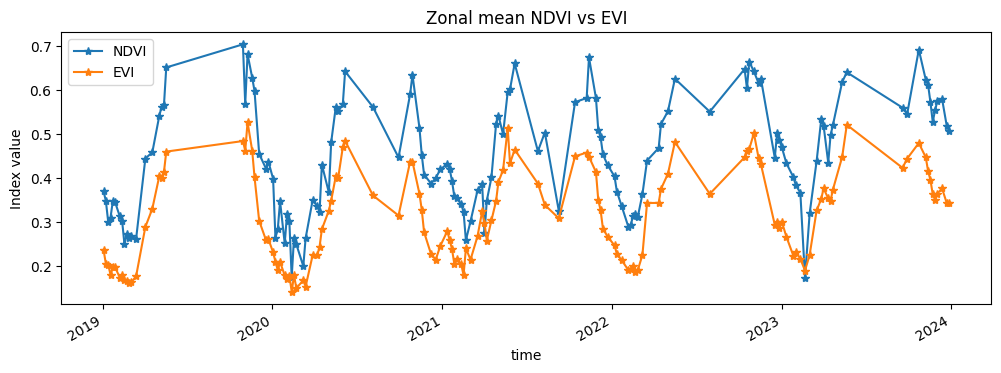

In [7]:
ts = ds[["NDVI", "EVI"]].mean(["x", "y"]).to_dataframe()[["NDVI", "EVI"]].dropna()
ts.plot(figsize=(12, 4), marker="*")
plt.title("Zonal mean NDVI vs EVI"); plt.ylabel("Index value");

NDVI peak mean: 0.7034114599227905 CV: 0.14240923616290632
EVI peak mean: 0.4841635823249817 CV: 0.22012281733273897
                NDVI       EVI
time                          
2019-01-01  0.453470  0.363694
2020-01-01  0.466825  0.341744
2021-01-01  0.414459  0.333131
2022-01-01  0.374834  0.313424
2023-01-01  0.517408  0.330360


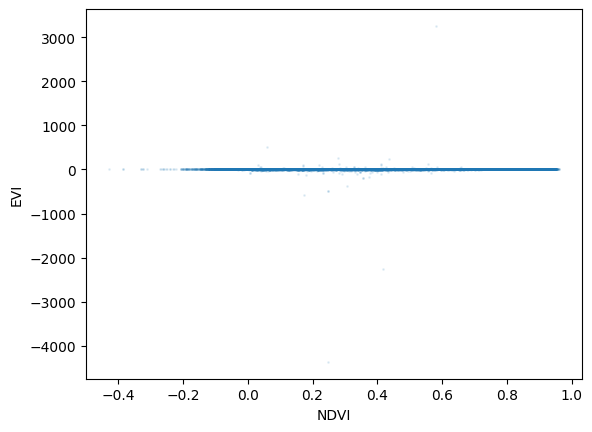

In [9]:
# (a) Scatter: NDVI flattens at high values while EVI keeps rising
ds.NDVI.values.ravel()  # flatten, then:
plt.scatter(ds.NDVI.values.ravel(), ds.EVI.values.ravel(), s=1, alpha=0.1)
plt.xlabel("NDVI"); plt.ylabel("EVI")

# (b) Spatial variability at the peak date: higher CV = better at separating fields
peak_t = ds.NDVI.mean(["x", "y"]).idxmax("time")
for idx in ["NDVI", "EVI"]:
    px = ds[idx].sel(time=peak_t)
    print(idx, "peak mean:", float(px.mean()), "CV:", float(px.std() / px.mean()))

# (c) Dynamic range per year (peak minus trough)
yr = ts.resample("YS").agg(lambda s: s.max() - s.min())
print(yr)

In [10]:
m = ts.resample("MS").mean()
clim = m.groupby(m.index.month).transform("mean")
sd = m.groupby(m.index.month).transform("std")
z = (m - clim) / sd

severe = z[(z.NDVI < -1.5) | (z.EVI < -1.5)]
print(severe)
print("Mean % below normal:", ((m - clim) / clim * 100).loc[severe.index].round(1))

                NDVI       EVI
time                          
2020-11-01 -1.722133 -1.581537
Mean % below normal:                  NDVI        EVI
time                            
2020-11-01 -20.799999 -22.299999
